# M5.8 · 统计显著性与 Bootstrap

> 回测收益可能只是运气。需要用 t 检验判断均值/Alpha 是否显著，并用 bootstrap 在不依赖正态假设的情况下给出置信区间。

## 一、方法

1. **均值 t 检验**：$t=\bar r/(s/\sqrt n)$，对应 p 值；
2. **Alpha/Beta 回归**：CAPM $r=\alpha+\beta b+\epsilon$，用 numpy 与 statsmodels 双实现对照；
3. **iid bootstrap**：重采样收益，得 Sharpe 分布与 95% 区间、Sharpe>0 概率；
4. **block bootstrap**：按块重采样，保留收益的时间自相关，区间通常更宽、更稳健。

## 二、t 检验与回归双实现

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from bt_lab2 import significance as sg
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
r1 = cl.pct_change(fill_method=None).iloc[-250:, 0].fillna(0)
bench = pd.read_csv(r'C:\Users\gucao\Desktop\Qlib\data\benchmark\000300_sh.csv',
                    parse_dates=['date']).set_index('date')['close']
b1 = bench.pct_change(fill_method=None).reindex(r1.index).fillna(0)
print('均值检验:', sg.mean_t_test(r1))
a_np = sg.alpha_beta_numpy(r1, b1); a_sm = sg.alpha_beta_statsmodels(r1, b1)
print('numpy : alpha=%.5f beta=%.4f' % (a_np['alpha'], a_np['beta']))
print('sm    : alpha=%.5f beta=%.4f' % (a_sm['alpha'], a_sm['beta']))
print('两实现 beta 差异=%.2e' % abs(a_np['beta']-a_sm['beta']))

[12792:MainThread](2026-11-05 15:24:22,127) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[12792:MainThread](2026-11-05 15:24:24,309) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[12792:MainThread](2026-11-05 15:24:24,310) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


均值检验: {'mean': -0.0007456741333007812, 't': -0.8698774275711552, 'p': 0.3852051671853821, 'n': 250}
numpy : alpha=-0.00079 beta=-0.0970
sm    : alpha=-0.00079 beta=-0.0970
两实现 beta 差异=4.16e-17


## 三、Bootstrap 区间

In [2]:
iid = sg.iid_bootstrap(r1, n_boot=500)
blk = sg.block_bootstrap(r1, block_len=20, n_boot=500)
print('iid   95%%CI[%.3f, %.3f] Sharpe>0概率=%.3f' % (iid['ci_low'], iid['ci_high'], iid['prob_positive']))
print('block 95%%CI[%.3f, %.3f] Sharpe>0概率=%.3f' % (blk['ci_low'], blk['ci_high'], blk['prob_positive']))

iid   95%CI[-2.703, 1.061] Sharpe>0概率=0.164
block 95%CI[-2.924, 1.375] Sharpe>0概率=0.272


## 四、可视化

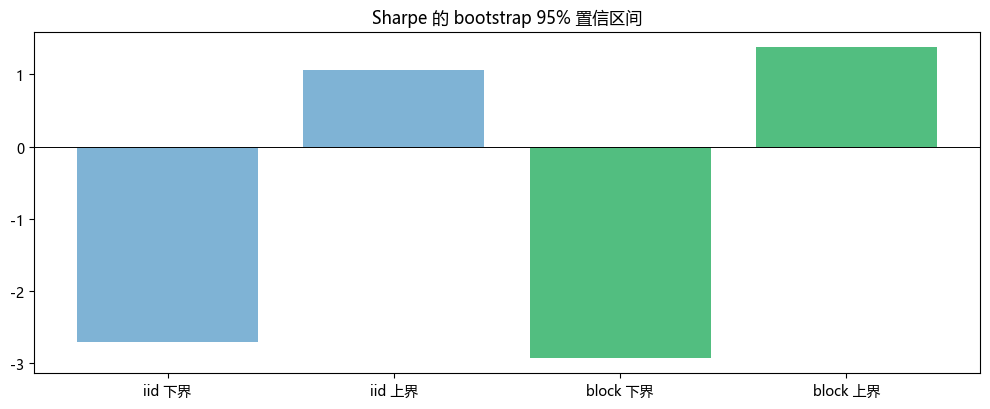

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(['iid 下界', 'iid 上界', 'block 下界', 'block 上界'],
       [iid['ci_low'], iid['ci_high'], blk['ci_low'], blk['ci_high']],
       color=['#7fb3d5', '#7fb3d5', '#52be80', '#52be80'])
ax.axhline(0, color='k', lw=0.7); ax.set_title('Sharpe 的 bootstrap 95% 置信区间')
plt.tight_layout(); plt.show()

## 五、面试要点

- **收益不服从正态时怎么办？** 用 bootstrap 等非参数方法，不依赖正态假设，直接由经验分布构造区间。
- **block bootstrap 解决什么？** 收益存在波动率聚集/自相关，按块重采样能保留这种时序结构，区间比 iid 更可靠。
- **p 值小就一定能赚钱吗？** 不是；统计显著只排除运气，还要看效应大小、成本、样本外表现与容量。
- **numpy 与 statsmodels 回归为何要对照？** 验证手写矩阵运算正确，两者系数应一致，差异在浮点精度内。

## 六、练习

1. 改变 block 长度，观察区间宽度。
2. 对 Alpha 而非 Sharpe 做 bootstrap。
3. 用 t 检验对比两只策略的收益差异。
4. 讨论小样本下 t 检验的局限。